# Alzheimer MRI — Train EfficientNet-B0


## 1. Setup
Import libraries, set random seeds, and select the compute device.


In [19]:
import os
from pathlib import Path
import random
from collections import Counter
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

# Set seed for reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# Detect and configure device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Using device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 2. Prepare Data and Splits
Recreate the exact stratified 70/15/15 train, validation, and test splits from Phase 2.


In [20]:
# Locate dataset
if Path('data/Alzheimer (Preprocessed Data)').exists():
    DATA_DIR = Path('data/Alzheimer (Preprocessed Data)')
elif Path('../data/Alzheimer (Preprocessed Data)').exists():
    DATA_DIR = Path('../data/Alzheimer (Preprocessed Data)')
else:
    DATA_DIR = Path('data/Alzheimer (Preprocessed Data)')

# Class mappings
class_folders = sorted([f for f in DATA_DIR.iterdir() if f.is_dir()])
class_names = [f.name for f in class_folders]
class_to_idx = {name: i for i, name in enumerate(class_names)}
idx_to_class = {i: name for name, i in class_to_idx.items()}

# Collect paths and labels
image_paths = []
labels = []
IMAGE_EXTS = {'.jpg', '.jpeg', '.png'}

for folder in class_folders:
    for f in folder.iterdir():
        if f.is_file() and f.suffix.lower() in IMAGE_EXTS:
            image_paths.append(f)
            labels.append(class_to_idx[folder.name])

# Stratified split: 70% train, 15% validation, 15% test (identical to Phase 2)
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths, labels, test_size=0.30, random_state=RANDOM_SEED, stratify=labels
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, random_state=RANDOM_SEED, stratify=temp_labels
)

print(f"Dataset splits: {len(train_paths)} train | {len(val_paths)} val | {len(test_paths)} test")
print(f"Classes ({len(class_names)}): {class_to_idx}")


Dataset splits: 4480 train | 960 val | 960 test
Classes (4): {'Mild_Demented': 0, 'Moderate_Demented': 1, 'Non_Demented': 2, 'Very_Mild_Demented': 3}


## 3. DataLoaders and Transforms
Configure training augmentation and deterministic validation transforms.


In [21]:
# ImageNet statistics for EfficientNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Transforms
train_transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomRotation(degrees=10),
    T.RandomHorizontalFlip(p=0.5),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

eval_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Simple PyTorch Dataset
class AlzheimerDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

# Datasets and DataLoaders
train_dataset = AlzheimerDataset(train_paths, train_labels, transform=train_transform)
val_dataset = AlzheimerDataset(val_paths, val_labels, transform=eval_transform)
test_dataset = AlzheimerDataset(test_paths, test_labels, transform=eval_transform)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"DataLoaders: {len(train_loader)} train batches | {len(val_loader)} val batches (batch_size={BATCH_SIZE})")


DataLoaders: 140 train batches | 30 val batches (batch_size=32)


## 4. Model Architecture
Define the EfficientNet-B0 architecture adapted for 4 classes.


In [22]:
def create_model(num_classes=4):
    """Creates a fresh EfficientNet-B0 initialized from pretrained weights."""
    # LINE BELOW DOWNLOADS PRETRAINED WEIGHTS ON FIRST RUN
    weights = models.EfficientNet_B0_Weights.DEFAULT
    fresh_model = models.efficientnet_b0(weights=weights)
    num_features = fresh_model.classifier[1].in_features
    fresh_model.classifier[1] = nn.Linear(num_features, num_classes)
    return fresh_model

# Verify output shape with dummy tensor
dummy_model = create_model(len(class_names)).to(device)
dummy_input = torch.randn(2, 3, 224, 224).to(device)
with torch.no_grad():
    dummy_output = dummy_model(dummy_input)

print(f"Model: EfficientNet-B0 adapted for {len(class_names)} classes")
print(f"Test output shape: {dummy_output.shape} (batch_size=2, num_classes={len(class_names)})")
del dummy_model, dummy_input, dummy_output


Model: EfficientNet-B0 adapted for 4 classes
Test output shape: torch.Size([2, 4]) (batch_size=2, num_classes=4)


## 5. Handle Class Imbalance
Calculate balanced class weights using training labels only and define weighted cross-entropy loss.


In [23]:
# Compute balanced class weights from training labels
train_counts = Counter(train_labels)
total_train_samples = len(train_labels)
num_classes = len(class_names)

# Balanced weight formula: total / (num_classes * count)
class_weights = [total_train_samples / (num_classes * train_counts[i]) for i in range(num_classes)]
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("Class weights (training set only):")
for i, name in idx_to_class.items():
    print(f"  {name:20s}: count={train_counts[i]:4d} | weight={class_weights[i]:.4f}")

# Loss function with class weighting
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)


Class weights (training set only):
  Mild_Demented       : count= 627 | weight=1.7863
  Moderate_Demented   : count=  45 | weight=24.8889
  Non_Demented        : count=2240 | weight=0.5000
  Very_Mild_Demented  : count=1568 | weight=0.7143


## 6. Training Configuration
Set hyperparameters: up to 15 epochs, AdamW optimizer, and early stopping with patience of 3.


In [24]:
# Training hyperparameters
LEARNING_RATE = 1e-4
EPOCHS = 15
PATIENCE = 3

print("Training Configuration:")
print(f" - Optimizer: AdamW (lr={LEARNING_RATE}, weight_decay=0.01)")
print(f" - Max Epochs: {EPOCHS}")
print(f" - Batch Size: {BATCH_SIZE}")
print(f" - Early Stopping Patience: {PATIENCE} epochs")
print(" - Metric Monitored: Validation Macro F1")
print("Note: If GPU runs out of memory, reduce BATCH_SIZE to 16 in Section 3.")


Training Configuration:
 - Optimizer: AdamW (lr=0.0001, weight_decay=0.01)
 - Max Epochs: 15
 - Batch Size: 32
 - Early Stopping Patience: 3 epochs
 - Metric Monitored: Validation Macro F1
Note: If GPU runs out of memory, reduce BATCH_SIZE to 16 in Section 3.


## 7. Training Loop with Early Stopping
Rerunning this cell starts a fresh training run initialized with pretrained weights.
The best model checkpoint is saved to `artifacts/best_efficientnet_b0.pth` whenever validation macro F1 improves.


In [25]:
# Setup project-root artifacts directory
PROJECT_ROOT = Path('..') if Path('../data').exists() else Path('.')
artifacts_dir = PROJECT_ROOT / 'artifacts'
artifacts_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = artifacts_dir / 'best_efficientnet_b0.pth'

# Initialize fresh model and optimizer so rerunning this cell starts a fresh experiment
model = create_model(len(class_names)).to(device)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-2)

# Tracking history and early stopping
history = {
    'train_loss': [],
    'val_loss': [],
    'val_acc': [],
    'val_f1': []
}

best_val_f1 = 0.0
patience_counter = 0

print(f"Starting training for up to {EPOCHS} epochs on {device} (patience={PATIENCE})...\n")
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    # --- Training Phase ---
    model.train()
    running_loss = 0.0
    
    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        
    epoch_train_loss = running_loss / len(train_dataset)
    
    # --- Validation Phase ---
    model.eval()
    val_loss = 0.0
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * images.size(0)
            
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
            
    epoch_val_loss = val_loss / len(val_dataset)
    epoch_val_acc = accuracy_score(all_targets, all_preds)
    epoch_val_f1 = f1_score(all_targets, all_preds, average='macro')
    
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)
    history['val_f1'].append(epoch_val_f1)
    
    print(f"Epoch {epoch:02d}/{EPOCHS:02d} - "
          f"Train Loss: {epoch_train_loss:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} | "
          f"Val Acc: {epoch_val_acc:.4f} | "
          f"Val Macro F1: {epoch_val_f1:.4f}")
    
    # Check for improvement in validation macro F1
    if epoch_val_f1 > best_val_f1:
        best_val_f1 = epoch_val_f1
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'class_to_idx': class_to_idx,
            'idx_to_class': idx_to_class,
            'val_f1': epoch_val_f1,
            'val_acc': epoch_val_acc,
            'history': history,
            'max_epochs': EPOCHS,
            'patience': PATIENCE
        }, checkpoint_path)
        print(f"  --> Best model saved! (Val Macro F1: {best_val_f1:.4f})")
    else:
        patience_counter += 1
        print(f"  --> No improvement. Early stopping counter: {patience_counter}/{PATIENCE}")
        if patience_counter >= PATIENCE:
            print(f"\nEarly stopping triggered: Validation Macro F1 did not improve for {PATIENCE} consecutive epochs.")
            break

total_time = time.time() - start_time
print(f"\nTraining completed in {total_time/60:.2f} minutes.")
print(f"Best validation macro F1: {best_val_f1:.4f}")
print(f"Best checkpoint preserved at: {checkpoint_path.resolve()}")


Starting training for up to 15 epochs on cuda (patience=3)...

Epoch 01/15 - Train Loss: 1.2233 | Val Loss: 1.0043 | Val Acc: 0.5510 | Val Macro F1: 0.4675
  --> Best model saved! (Val Macro F1: 0.4675)
Epoch 02/15 - Train Loss: 0.9595 | Val Loss: 0.7347 | Val Acc: 0.6125 | Val Macro F1: 0.5378
  --> Best model saved! (Val Macro F1: 0.5378)
Epoch 03/15 - Train Loss: 0.7694 | Val Loss: 0.6208 | Val Acc: 0.6573 | Val Macro F1: 0.7013
  --> Best model saved! (Val Macro F1: 0.7013)
Epoch 04/15 - Train Loss: 0.6680 | Val Loss: 0.5426 | Val Acc: 0.7177 | Val Macro F1: 0.7422
  --> Best model saved! (Val Macro F1: 0.7422)
Epoch 05/15 - Train Loss: 0.5955 | Val Loss: 0.4776 | Val Acc: 0.7312 | Val Macro F1: 0.7778
  --> Best model saved! (Val Macro F1: 0.7778)
Epoch 06/15 - Train Loss: 0.5301 | Val Loss: 0.3853 | Val Acc: 0.7740 | Val Macro F1: 0.8075
  --> Best model saved! (Val Macro F1: 0.8075)
Epoch 07/15 - Train Loss: 0.4100 | Val Loss: 0.3156 | Val Acc: 0.8208 | Val Macro F1: 0.8542
  --

## 8. Training Curves
Plot loss, validation accuracy, and validation macro F1 across completed epochs.


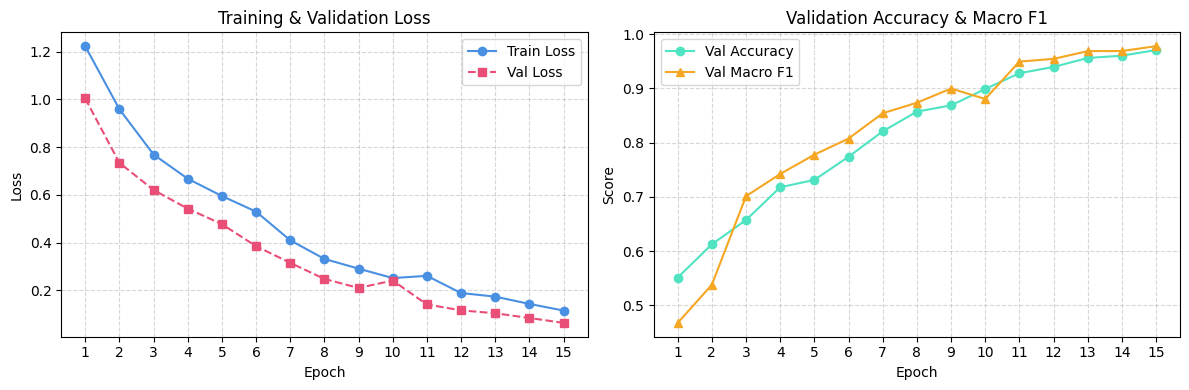

In [26]:
if history['train_loss']:
    epochs_range = list(range(1, len(history['train_loss']) + 1))
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    
    # Loss plot
    ax1.plot(epochs_range, history['train_loss'], 'o-', label='Train Loss', color='#4A90E2')
    ax1.plot(epochs_range, history['val_loss'], 's--', label='Val Loss', color='#E94E77')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title('Training & Validation Loss')
    ax1.set_xticks(epochs_range)
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.5)
    
    # Metric plot
    ax2.plot(epochs_range, history['val_acc'], 'o-', label='Val Accuracy', color='#50E3C2')
    ax2.plot(epochs_range, history['val_f1'], '^-', label='Val Macro F1', color='#F5A623')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Score')
    ax2.set_title('Validation Accuracy & Macro F1')
    ax2.set_xticks(epochs_range)
    ax2.legend()
    ax2.grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.show()
else:
    print('No training history available. Run Section 7 to train the model and generate curves.')


## 9. Reload and Verify Best Model
Demonstrate reloading the saved checkpoint into a fresh model architecture.


In [27]:
PROJECT_ROOT = Path('..') if Path('../data').exists() else Path('.')
checkpoint_path = PROJECT_ROOT / 'artifacts' / 'best_efficientnet_b0.pth'

if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location=device)
    
    reloaded_model = create_model(len(class_names))
    reloaded_model.load_state_dict(checkpoint['model_state_dict'])
    reloaded_model = reloaded_model.to(device)
    reloaded_model.eval()
    
    print('Checkpoint successfully reloaded:')
    print(f" - Location: {checkpoint_path.resolve()}")
    print(f" - Best Model Epoch: {checkpoint['epoch']}")
    print(f" - Best Val Macro F1: {checkpoint['val_f1']:.4f}")
    print(f" - Best Val Accuracy: {checkpoint['val_acc']:.4f}")
    print(f" - Label Mapping: {checkpoint['class_to_idx']}")
else:
    print(f"Checkpoint not found at: {checkpoint_path.resolve()}")
    print("Run Section 7 to train and save the model checkpoint.")


Checkpoint successfully reloaded:
 - Location: C:\Users\usern\Desktop\Alzheimer-Detection\artifacts\best_efficientnet_b0.pth
 - Best Model Epoch: 15
 - Best Val Macro F1: 0.9780
 - Best Val Accuracy: 0.9708
 - Label Mapping: {'Mild_Demented': 0, 'Moderate_Demented': 1, 'Non_Demented': 2, 'Very_Mild_Demented': 3}


## 10. Summary and Next Steps
- **Model:** Pretrained EfficientNet-B0 adapted for 4 classes.
- **Training Strategy:** Up to 15 epochs with early stopping (patience=3) monitoring validation macro F1.
- **Class Balancing:** Weighted cross-entropy loss addresses the 50:1 imbalance of `Moderate_Demented`.
- **Checkpoint:** Best model selected by validation macro F1 and saved locally to `artifacts/best_efficientnet_b0.pth`.
- **Test Set:** Held-out test set remained untouched and will be evaluated in Phase 4.
